# Exercice 2 — Mini-GPT depuis zéro

Ce modèle n'utilise aucun poids Hugging Face. Il apprend à prédire le **caractère
suivant** dans `corpus.txt`, un texte original écrit pour l'exercice.

Le contexte vaut 64 caractères. Les embeddings de caractères et de positions
ont la dimension 64. Deux blocs pré-normalisés utilisent quatre têtes.
Le réseau interne fait `64 → 256 → 64` avec GELU. La projection finale couvre
le vocabulaire de caractères.

La cible est décalée d'un caractère. La perte d'entropie croisée est calculée
sur **toutes** les positions, pas seulement la dernière.
        

In [1]:
import sys
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.training import count_parameters, get_device, set_seed

set_seed(42)
device = get_device()
print("Dossier du projet :", ROOT)
print("Périphérique :", device)

Dossier du projet : /Users/hmid/Downloads/Deep-Learning-Transformers
Périphérique : mps


## 1. Vocabulaire de caractères

`stoi` donne un numéro à chaque caractère. `itos` fait le chemin inverse.
Pour une entrée qui se termine visuellement par `Bonjou`, la cible est le texte
décalé : chaque position apprend le caractère qui vient juste après.
        

In [2]:
from src.data import load_char_corpus, split_token_stream

texte, stoi, itos, tokens = load_char_corpus(ROOT / "corpus.txt")
tokens_train, tokens_val = split_token_stream(tokens, train_ratio=0.9)
print("Caractères :", len(texte))
print("Taille du vocabulaire :", len(stoi))
print("Tokens train / validation :", len(tokens_train), len(tokens_val))
print("Extrait :", repr(texte[:80]))

exemple = "Bonjou"
print("Décalage pédagogique, si les caractères existent dans le vocabulaire :")
print("entrée :", exemple[:-1])
print("cible  :", exemple[1:])

contexte = 64
x_demo = tokens[:contexte]
y_demo = tokens[1:contexte + 1]
print("Forme d'une fenêtre réelle :", tuple(x_demo.shape), "->", tuple(y_demo.shape))
print("Entrée :", repr("".join(itos[int(i)] for i in x_demo[:40])), "...")
print("Cible  :", repr("".join(itos[int(i)] for i in y_demo[:40])), "...")
        

Caractères : 13400
Taille du vocabulaire : 70
Tokens train / validation : 12060 1340
Extrait : 'Le transformeur lit une séquence et prédit le caractère suivant. Cette phrase ou'
Décalage pédagogique, si les caractères existent dans le vocabulaire :
entrée : Bonjo
cible  : onjou
Forme d'une fenêtre réelle : (64,) -> (64,)
Entrée : 'Le transformeur lit une séquence et préd' ...
Cible  : 'e transformeur lit une séquence et prédi' ...


## 2. Masque causal et entraînement

`True` dans le masque signifie : cette paire est interdite. Le triangle
supérieur, diagonale exclue, cache le futur.

L'entraînement dure 60 époques de 80 lots de 32 fenêtres. Ce budget n'est pas
imposé par le TP : il reste raisonnable sur CPU. Adam utilise un pas de 0,003,
choix de travail puisque le sujet ne fixe pas le pas. Le meilleur état selon
la perte de validation est rechargé avant la génération.
        

In [3]:
from src.text_models import MiniGPT, causal_mask
from src.training import train_language_model

masque = causal_mask(8)
print("Masque 8 x 8, True = interdit :")
print(masque.int().numpy())

set_seed(42)
mini_gpt = MiniGPT(vocab_size=len(stoi), context=64, dropout=0.0)
print("Paramètres :", count_parameters(mini_gpt))
historique = train_language_model(
    mini_gpt,
    tokens_train,
    tokens_val,
    context=64,
    epochs=60,
    steps_per_epoch=80,
    batch_size=32,
    lr=3e-3,
    device=device,
    seed=42,
)
        

Masque 8 x 8, True = interdit :
[[0 1 1 1 1 1 1 1]
 [0 0 1 1 1 1 1 1]
 [0 0 0 1 1 1 1 1]
 [0 0 0 0 1 1 1 1]
 [0 0 0 0 0 1 1 1]
 [0 0 0 0 0 0 1 1]
 [0 0 0 0 0 0 0 1]
 [0 0 0 0 0 0 0 0]]
Paramètres : 113094


Epoch   1 | train 2.6095 | val 2.4652  <- meilleur


Epoch   2 | train 2.2511 | val 2.3088  <- meilleur


Epoch   3 | train 2.0057 | val 2.1252  <- meilleur


Epoch   4 | train 1.7349 | val 2.0535  <- meilleur


Epoch   5 | train 1.5070 | val 2.0281  <- meilleur


... (51 outputs left out)

Epoch  57 | train 0.1860 | val 4.8805


Epoch  58 | train 0.1832 | val 5.0715


Epoch  59 | train 0.1849 | val 5.1209


Epoch  60 | train 0.1845 | val 5.1750
Meilleur mini-GPT restauré, perte de validation 2.0281


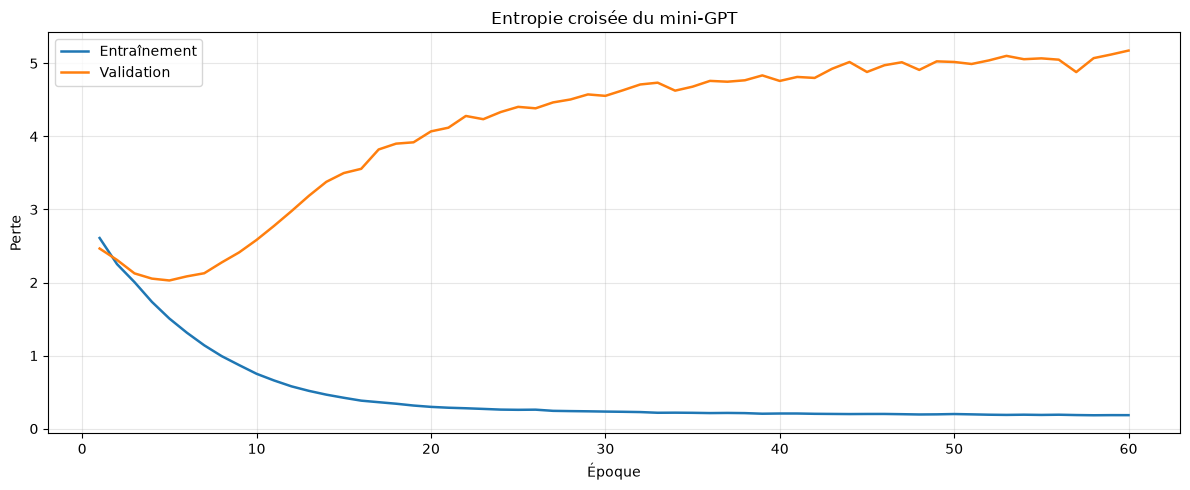


Température 0.5
Le transformeur lit une séquence et prédit le coucué décite. Le de tour de la couche la déciple de l'avecter de de de la la sonne d'exerre dour de la donne le matin, pas le carache d'exe résuite la de connésit de le cormencure le suite la d'anson



Température 1.0
Le transformeur lit une séquence et prédit le à déjéqu'heure quédé nante. La ménédient la néparage. Le de sérofdemedi sées poin quis. La vansurenal. Da appuit minte, pau la caragendri. On mal. La soune tinge poyensuie, on nue posituat. Ilutencut 



Température 1.5
Le transformeur lit une séquence et prédit le à. On à le tirtexerd. Un jeune a cydïen. On iténe heure, de soublé médi séranne hore, . La vanlietuan. écorteule heure, quance lantehmali. On mahdad l'etremens hPour lempaie pôburqui. Lhs-orpuite ente


In [4]:
from src.evaluation import plot_loss_curves, save_figure, save_json
from src.text_models import decode_ids, generate_characters

figure = plot_loss_curves(
    {
        "Entraînement": [ligne["train_loss"] for ligne in historique],
        "Validation": [ligne["val_loss"] for ligne in historique],
    },
    "Entropie croisée du mini-GPT",
    ylabel="Perte",
)
save_figure(figure, ROOT / "outputs" / "figures" / "04_minigpt_pertes.png")
plt.show()

amorce = "Le transformeur lit une séquence et prédit le "
identifiants = torch.tensor([[stoi[caractere] for caractere in amorce]], dtype=torch.long)
generations = {}
for temperature in (0.5, 1.0, 1.5):
    generateur = torch.Generator().manual_seed(42)
    suite = generate_characters(
        mini_gpt, identifiants, n_new=200, temperature=temperature,
        device=device, generator=generateur,
    )
    texte_complet = decode_ids(suite[0], itos)
    generations[str(temperature)] = texte_complet
    print("\n" + "=" * 72)
    print(f"Température {temperature}")
    print(texte_complet)
        

## 3. Test obligatoire de causalité

En mode `eval()`, on modifie un caractère situé après la position 20.
Les logits des positions 0 à 19 ne doivent pas changer. Si elles changeaient,
le bloc aurait lu le futur.
        

In [5]:
mini_gpt.eval()
lot = tokens_train[:64].unsqueeze(0).clone()
modifie = lot.clone()
position = 20
modifie[0, position] = (modifie[0, position] + 1) % len(stoi)
with torch.no_grad():
    avant = mini_gpt(lot.to(device)).cpu()
    apres = mini_gpt(modifie.to(device)).cpu()
ecart = (avant[:, :position] - apres[:, :position]).abs().max().item()
print(f"Écart maximal sur les logits passés : {ecart:.3e}")
if ecart > 1e-5:
    raise RuntimeError("Le masque causal ne protège pas les positions passées.")
print("Les positions antérieures sont inchangées.")

save_json(ROOT / "outputs" / "metrics" / "04_minigpt.json", {
    "device": str(device),
    "vocabulaire": len(stoi),
    "caracteres": len(texte),
    "perte_finale": historique[-1],
    "meilleure_validation": min(ligne["val_loss"] for ligne in historique),
    "generations": generations,
    "ecart_causal": ecart,
})
        

Écart maximal sur les logits passés : 0.000e+00
Les positions antérieures sont inchangées.


PosixPath('/Users/hmid/Downloads/Deep-Learning-Transformers/outputs/metrics/04_minigpt.json')

## Questions

### Que se passe-t-il si l'on retire le masque pendant l'entraînement ?

Le test ci-dessus montre le mécanisme, pas un second entraînement : avec le
masque, changer le futur ne change pas le passé. Sans masque, une position
pourrait lire la cible située plus loin dans la même fenêtre. La tâche deviendrait
artificiellement facile. À la génération, ce futur n'existe pas encore, donc
le modèle serait utilisé dans une situation qu'il n'a pas apprise. Cette
conséquence sur la qualité du texte n'a pas été mesurée par un entraînement
sans masque : elle suit directement du décalage entre entraînement et génération.

### Quel effet a la température ?

Les trois textes de 200 caractères sont produits avec la même amorce et la même
graine de tirage. Une température de 0,5 rend la distribution plus piquée :
le modèle répète davantage les enchaînements qu'il juge probables. Une température
de 1,0 laisse les probabilités telles quelles. Une température de 1,5 les aplatit
et laisse apparaître des caractères plus inattendus. Il faut comparer les textes
affichés, sans prétendre qu'un petit corpus produit une prose littéraire.

### Pourquoi décaler les cibles ?

Le modèle reçoit des caractères déjà connus et doit dire celui qui vient après.
Si la cible n'était pas décalée, il apprendrait à recopier l'entrée. L'exemple
`Bonjou` le montre : l'entrée `Bonjo` a pour cible `onjou`. Dans le tenseur réel,
`y` commence un caractère après `x` et se termine un caractère plus loin.
        

## Résultats mesurés de cette exécution

Vocabulaire : 70 caractères. Meilleure perte de validation : 2,028. Dernière époque : entraînement 0,185, validation 5,175. Le modèle générateur est celui de la meilleure validation. Le test causal donne un écart de 0 sur les logits passés.

Les trois textes de 200 caractères montrent une dispersion croissante de 0,5 à 1,5. Ils ne forment pas du français correct : le corpus est court et le modèle surapprend. La température change le tirage, elle ne répare pas cette limite.